# Optics matching with Xopt

This example follows PyTutorial 4, replacing SciPy's minimizer with **Xopt**, the optimization library developed at SLAC. The lattice, beam, and matching merit are the same.

If needed, run `%pip install xopt` in a separate cell and restart the kernel. RF-Track must also be installed. See the [Xopt documentation](https://xopt.xopt.org/) for more examples.

In [1]:
import RF_Track as rft
import numpy as np
import matplotlib.pyplot as plt

## Bunch parameters

In [2]:
# Bunch parameters
mass = rft.electronmass # MeV/c^2
charge = -1 # single-particle charge, in units of e
population = 1*rft.nC # number of real particles per bunch
Pc = 5 # reference momentum, MeV/c
P_Q = Pc / charge # MV/c, reference rigidity

## FODO cell parameters

In [3]:
# FODO cell parameters
Lcell = 2 # m
Lquad = 0.2 # m
Ldrift = Lcell/2 - Lquad # m

mu = np.deg2rad(90) # deg
k1L = np.sin(mu/2) / (Lcell/4) # 1/m

strength = k1L * P_Q # MeV/m

## Define the elements

In [4]:
# Half a focusing quadrupole
Qf = rft.Quadrupole(Lquad/2, strength/2)

# A full, defocusing, quadrupole
QD = rft.Quadrupole(Lquad, -strength)

# The Drift
Dr = rft.Drift(Ldrift)

# Define a lattice with 10 FODO cells

In [5]:
# Define the FODO cell
FODO = rft.Lattice()
FODO.append(Qf)
FODO.append(Dr)
FODO.append(QD)
FODO.append(Dr)
FODO.append(Qf)

# Create the full lattice by repeating the FODO cell 10 times
L = rft.Lattice()
for _ in range(10):
    L.append(FODO)

# ...and a bunch

In [6]:
# Define Twiss parameters
Twiss = rft.Bunch6d_twiss()
Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
Twiss.emitt_y = 0.001 # mm.mrad
Twiss.alpha_x = 0.0
Twiss.alpha_y = 0.0
Twiss.beta_x = Lcell * (1 + np.sin(mu/2)) / np.sin(mu) # m
Twiss.beta_y = Lcell * (1 - np.sin(mu/2)) / np.sin(mu) # m

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [7]:
print(Twiss.beta_x)
print(Twiss.beta_y)

3.414213562373095
0.5857864376269051


# Then, we can perform tracking

In [8]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

We can query the lattice to obtain, for example, the Twiss parameters and emittance.

In [9]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y');

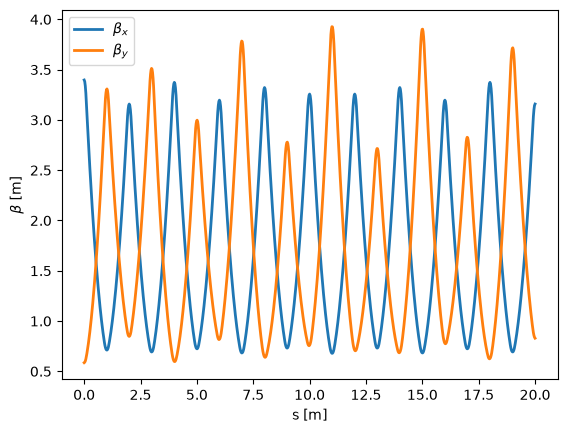

In [10]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Now we can match the Twiss parameters to be periodic
## Start with defining a merit function
This function returns zero when the initial and final beta functions are equal and the initial and final alpha functions are equal:
\begin{align*}
\chi^{2}= & \left(\beta_{x,\text{ final}}-\beta_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\beta_{y,\text{ final}}-\beta_{y,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{x,\text{ final}}-\alpha_{x,\text{ initial}}\right)^{2}+\cdots\\
 & \left(\alpha_{y,\text{ final}}-\alpha_{y,\text{ initial}}\right)^{2}
\end{align*}

Here the beta residuals are expressed in metres and the alpha residuals are dimensionless. This simple merit keeps the original tutorial's weighting; for a real matching specification, divide each residual by its required tolerance.

In [11]:
def match_Twiss(twiss, FODO):

    beta_x = twiss[0] # m
    beta_y = twiss[1] # m
    alpha_x = twiss[2]
    alpha_y = twiss[3]
    
    # Create a bunch with initial beta_x and beta_y from 'twiss'
    Twiss = rft.Bunch6d_twiss()
    Twiss.emitt_x = 0.001 # mm.mrad, normalized emittances
    Twiss.emitt_y = 0.001 # mm.mrad
    Twiss.beta_x = beta_x # m
    Twiss.beta_y = beta_y # m
    Twiss.alpha_x = alpha_x #
    Twiss.alpha_y = alpha_y #
    
    # Create the bunch
    B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)
    
    # Perform tracking
    B1 = FODO.track(B0)
    I1 = B1.get_info()

    # Compute the merit function
    M = ((I1.beta_x - beta_x) ** 2 +
         (I1.beta_y - beta_y) ** 2 +
         (I1.alpha_x - alpha_x) ** 2 +
         (I1.alpha_y - alpha_y) ** 2)

    return M

## Let Xopt choose the next trial

Xopt needs three things: the **variables and their bounds**, an **evaluator** that runs our calculation, and a **generator** that chooses new trials. We use expected improvement: it learns from previous results to balance searching uncertain regions with improving the best match. Xopt handles the Bayesian model internally.

The evaluator receives a dictionary of named inputs and returns a dictionary of results. This small wrapper lets us reuse `match_Twiss` unchanged.

In [12]:
from xopt import Xopt
from xopt.vocs import VOCS
from xopt.evaluator import Evaluator
from xopt.generators.bayesian import ExpectedImprovementGenerator

parameter_names = ["beta_x", "beta_y", "alpha_x", "alpha_y"]

def evaluate_matching(inputs):
    twiss = [inputs[name] for name in parameter_names]
    return {"merit": match_Twiss(twiss, FODO)}

# Variable and Objective Constraint Settings
vocs = VOCS(
    variables={
        "beta_x": [2.5, 4.5],  # m
        "beta_y": [0.4, 1.0],  # m
        "alpha_x": [-0.3, 0.3],
        "alpha_y": [-0.3, 0.3],
    },
    objectives={"merit": "MINIMIZE"},
)

X = Xopt(
    vocs=vocs,
    evaluator=Evaluator(function=evaluate_matching),
    generator=ExpectedImprovementGenerator(vocs=vocs),
)

## Run the optimization

We use a modest search box around the thin-lens estimate, keeping both beta functions positive. Widen these bounds if the lattice changes.

First evaluate the original guess and a few random trials. Then each `X.step()` proposes one new set of Twiss parameters, tracks the beam, and stores the result in `X.data`. We minimize the original merit directly, without a sign change or logarithmic transformation.

In [13]:
initial_guess = dict(zip(parameter_names, [Twiss.beta_x, Twiss.beta_y, 0.0, 0.0]))
X.evaluate_data([initial_guess])
X.random_evaluate(15, seed=42)

n_steps = 80
for step in range(n_steps):
    X.step()
    if (step + 1) % 10 == 0:
        print(f"Step {step + 1}: best merit = {X.data['merit'].min():.6g}")

# Select the best point actually evaluated, keeping the original parameter order.
best = X.data.loc[X.data["merit"].idxmin()]
matched_twiss = best[parameter_names].to_numpy(dtype=float)
print("Matched [beta_x, beta_y, alpha_x, alpha_y]:", matched_twiss)
print(f"Merit: {X.data['merit'].iloc[0]:.6g} -> {best['merit']:.6g}")

Step 10: best merit = 0.00346933
Step 20: best merit = 0.00346933
Step 30: best merit = 0.00346933
Step 40: best merit = 0.00346933
Step 50: best merit = 0.00228076
Step 60: best merit = 0.00228076
Step 70: best merit = 0.00228076
Step 80: best merit = 0.00190503
Matched [beta_x, beta_y, alpha_x, alpha_y]: [ 3.27877245  0.69629014 -0.01123204 -0.00496   ]
Merit: 0.135161 -> 0.00190503


The iteration budget is not a convergence guarantee. Inspect the best merit so far, then check how nearly the beta functions repeat through the ten FODO cells. The random initialization is seeded; Bayesian proposals can still vary between runs.

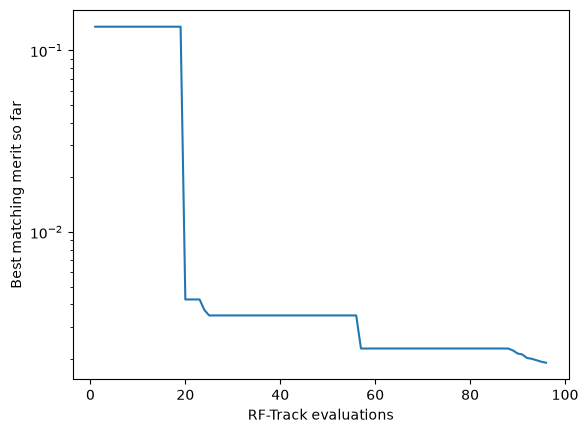

In [14]:
plt.semilogy(np.arange(1, len(X.data) + 1), X.data["merit"].cummin().clip(lower=1e-16))
plt.xlabel("RF-Track evaluations")
plt.ylabel("Best matching merit so far")
plt.show()

Let's create a beam with the matched beta functions

In [15]:
Twiss.beta_x = matched_twiss[0]
Twiss.beta_y = matched_twiss[1]
Twiss.alpha_x = matched_twiss[2]
Twiss.alpha_y = matched_twiss[3]

# Create the bunch
B0 = rft.Bunch6d_QR (mass, population, charge, Pc, Twiss, 1000)

In [16]:
L.set_tt_nsteps(1000)
B1 = L.track(B0)

In [17]:
T = L.get_transport_table('%S %beta_x %beta_y %emitt_x %emitt_y %sigma_x %sigma_y')

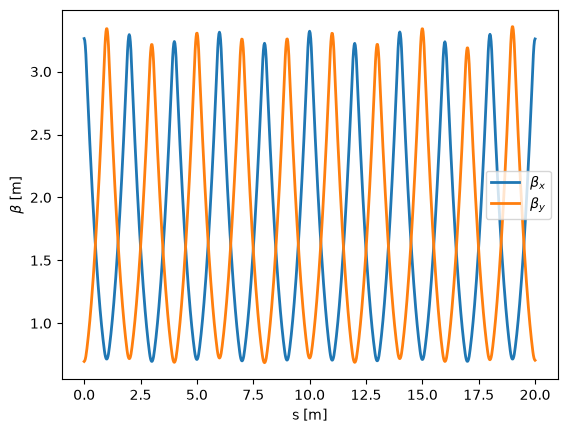

In [18]:
plt.plot(T[:,0], T[:,1], linewidth=2, label=r'$\beta_x$')
plt.plot(T[:,0], T[:,2], linewidth=2, label=r'$\beta_y$')
plt.legend()
plt.xlabel('s [m]')
plt.ylabel(r'$\beta$ [m]')
plt.show()

# Exercises

## Exercise 1 — Explore the evaluation budget

Try different values of `n_steps` and different numbers of initial random trials. Rerun from the cell that creates `X` for each fresh optimization. Compare the best merit and the number of RF-Track evaluations. How close is the result to the original SciPy example?

Widen the variable bounds and repeat. Why can a physically informed search range help?

Finally, add a penalty $\lambda(\beta_x^2+\beta_y^2)$ to the merit and investigate the compromise between periodicity and beam size.

In [19]:
# Your solution